# S-D v2: During-Inference Ensemble M1→M4 with Confidence Scores

**Arsitektur:** M1 (detector) → M4 (confidence-aware reviewer)

Sama seperti S-C (M1→M4) tapi M4 sekarang output:
- FIRST READER EVALUATION
- MY OBSERVATIONS
- CLASSIFICATION
- **CONFIDENCE (0-100%)**
- **KEY EVIDENCE**

M1 data di-REUSE dari Exp1 v2 (tidak perlu run M1 lagi).

**Kenapa bukan M4→M1 (reversed)?**
M1 (NV-Reason-CXR) punya format output hardcoded dari training (`<think>/<answer>`) 
dan tidak bisa mengikuti template custom. M4 (MedGemma) bisa follow structured prompts.

**Aggregation Strategies:**
- D1: M4 reviewer decision (binary)
- D2: Confidence-weighted (M4 confidence × prediction)
- D3: Threshold cascade (high/low confidence routing)
- D4: Agreement-aware (M1 original + M4 reviewer)

## 1 — Setup & Imports

In [2]:
import sys
import json
import time
import re
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm

# Add src to path
sys.path.insert(0, str(Path('.').resolve() / 'src'))

from during_ensemble import (
    load_m1_results,
    get_m1_output,
    build_reviewer_user_text,
    build_few_shot_context_v2,
    load_checkpoint,
    append_jsonl,
    USER_QUERY_REVIEWER,
)
from evaluate import extract_diagnosis, compute_classification_metrics

print(f'PyTorch: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name()}')
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

PyTorch: 2.10.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 5090
VRAM: 33.7 GB


## 2 — Configuration

In [3]:
# ════════════════════════════════════════════════════════════════════
# KONFIGURASI — SESUAIKAN PATH INI
# ════════════════════════════════════════════════════════════════════

# Model M4 (MedGemma-4B-IT) — path ke model weights
M4_MODEL_PATH = "../models/MedGemma-4B-IT"  # <-- SESUAIKAN

# M1 existing results (dari Exp1 v2)
M1_RESULTS_PATH = Path("result-M1/all_results.jsonl")

# Few-shot example pool CSVs
CHEXPERT_PTX_CSV  = "../data/chexpert_ptx_positive.csv"   # <-- SESUAIKAN
CHEXPERT_NORM_CSV = "../data/chexpert_ptx_negative.csv"   # <-- SESUAIKAN

# Test set image directories
CHEXPERT_TEST_NORMAL_DIR = "../data/chexpert_plus/images/internal_test_normal"  # <-- SESUAIKAN
CHEXPERT_TEST_PTX_DIR    = "../data/chexpert_plus/images/internal_test_pneumothorax"  # <-- SESUAIKAN
CHEXPERT_TEST_CSV        = "../data/chexpert_internal_test.csv"  # <-- SESUAIKAN

RSUNAIR_IMAGES_NORMAL = "../data/rs_unair/images/normal"  # <-- SESUAIKAN
RSUNAIR_IMAGES_PTX    = "../data/rs_unair/images/pneumothorax"  # <-- SESUAIKAN
RSUNAIR_LABELS_CSV    = "../data/rs_unair/labels.csv"  # <-- SESUAIKAN

# Few-shot image pool root (untuk example_selector)
POOL_IMAGES_ROOT = "../data/chexpert_plus/images"  # <-- SESUAIKAN

# Experiment config — k=8 ditambahkan untuk S-D
K_SHOTS = [0, 1, 4, 8]
SEEDS = [0, 1, 2, 3, 4]
MAX_NEW_TOKENS = 1024
TEMPERATURE = 0.1
TOP_P = 0.9

# Output
OUTPUT_DIR = Path("results-sd-v2-m1-m4-confidence")
OUTPUT_DIR.mkdir(exist_ok=True)
CHECKPOINT_PATH = OUTPUT_DIR / "checkpoint_sd_v2.jsonl"

print("Config loaded.")
print(f"  M4 model: {M4_MODEL_PATH}")
print(f"  K-shots: {K_SHOTS}")
print(f"  Seeds: {SEEDS}")
print(f"  Output: {OUTPUT_DIR}")

Config loaded.
  M4 model: ../models/MedGemma-4B-IT
  K-shots: [0, 1, 4, 8]
  Seeds: [0, 1, 2, 3, 4]
  Output: results-sd-v2-m1-m4-confidence


## 3 — Load M1 Existing Results

In [4]:
df_m1 = load_m1_results(M1_RESULTS_PATH)

# Filter to k_shots we need
df_m1_filtered = df_m1[df_m1['k_shot'].isin(K_SHOTS)].copy()
print(f"\nFiltered M1 results: {len(df_m1_filtered)} records")
print(f"  k_shots: {sorted(df_m1_filtered['k_shot'].unique())}")

# Check if k=8 data exists
for k in K_SHOTS:
    n = len(df_m1_filtered[df_m1_filtered['k_shot'] == k])
    print(f"  k={k}: {n} records {'✓' if n > 0 else '✗ MISSING'}")

Loaded M1 results: 11950 records
  k_shots: [np.int64(0), np.int64(1), np.int64(2), np.int64(4), np.int64(8)]
  seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  test_sets: ['CheXpert Plus (Internal)', 'RS UNAIR (External)']

Filtered M1 results: 9560 records
  k_shots: [np.int64(0), np.int64(1), np.int64(4), np.int64(8)]
  k=0: 2390 records ✓
  k=1: 2390 records ✓
  k=4: 2390 records ✓
  k=8: 2390 records ✓


## 4 — Load Few-Shot Example Selector

In [5]:
try:
    from example_selector import FewShotSelector
    selector = FewShotSelector(
        positive_csv=CHEXPERT_PTX_CSV,
        negative_csv=CHEXPERT_NORM_CSV,
        images_root=POOL_IMAGES_ROOT,
    )
    USE_SELECTOR = True
    print(f"FewShotSelector loaded: {len(selector.positives)} pos, {len(selector.negatives)} neg")
except Exception as e:
    print(f"Warning: Could not load FewShotSelector: {e}")
    USE_SELECTOR = False

[FewShotSelector] Pool loaded — PTX: 150, Normal: 150
FewShotSelector loaded: 150 pos, 150 neg


## 5 — Load Test Sets

In [6]:
def load_test_images(csv_path, normal_dir, ptx_dir, name):
    """Load test set image paths and labels."""
    df = pd.read_csv(csv_path)
    rows = []
    
    if 'file_id' in df.columns:
        # CheXpert format
        for _, r in df.iterrows():
            fid = r['file_id']
            label_int = 1 if r['label'] == 'pneumothorax' else 0
            img_dir = ptx_dir if label_int == 1 else normal_dir
            img_path = Path(img_dir) / f"{fid}.jpg"
            if not img_path.exists():
                img_path = Path(img_dir) / f"{fid}.png"
            rows.append({'image_id': fid, 'ground_truth': label_int, 'image_path': str(img_path)})
    elif 'image_id' in df.columns:
        # RS UNAIR format
        for _, r in df.iterrows():
            fname = r['image_id']
            if not fname.endswith(('.png', '.jpg')):
                fname = f"{fname}.png"
            label_int = int(r['label'])
            img_dir = ptx_dir if label_int == 1 else normal_dir
            img_path = Path(img_dir) / fname
            rows.append({'image_id': Path(fname).stem, 'ground_truth': label_int, 'image_path': str(img_path)})
    else:
        raise ValueError(f"Unknown CSV format: {df.columns.tolist()}")
    
    result = pd.DataFrame(rows)
    print(f"  {name}: {len(result)} images (PTX={result['ground_truth'].sum()}, Normal={(result['ground_truth']==0).sum()})")
    return result


print("Loading test sets...")
test_sets = [
    {
        'name': 'CheXpert Plus (Internal)',
        'df': load_test_images(CHEXPERT_TEST_CSV, CHEXPERT_TEST_NORMAL_DIR, CHEXPERT_TEST_PTX_DIR, 'CheXpert'),
    },
    {
        'name': 'RS UNAIR (External)',
        'df': load_test_images(RSUNAIR_LABELS_CSV, RSUNAIR_IMAGES_NORMAL, RSUNAIR_IMAGES_PTX, 'RS UNAIR'),
    },
]

total_images = sum(len(ts['df']) for ts in test_sets)
total_inferences = total_images * len(K_SHOTS) * len(SEEDS)
print(f"\nTotal inferences needed: {total_inferences}")
print(f"  = {total_images} images × {len(K_SHOTS)} k-shots × {len(SEEDS)} seeds")

Loading test sets...
  CheXpert: 200 images (PTX=100, Normal=100)
  RS UNAIR: 278 images (PTX=173, Normal=105)

Total inferences needed: 9560
  = 478 images × 4 k-shots × 5 seeds


## 6 — Load M4 Model (MedGemma-4B-IT, Gemma 3)

**PENTING:** Gemma 3 harus di-load dengan `bfloat16` compute dtype. float16 menyebabkan pad token overflow.

In [7]:
from transformers import AutoProcessor, BitsAndBytesConfig
from transformers import Gemma3ForConditionalGeneration

print(f"Loading M4 model: {M4_MODEL_PATH}")
print("Architecture: Gemma 3 (MedGemma-4B-IT)")
print("Quantization: 4-bit NF4 (bfloat16 compute)")

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
)

m4_processor = AutoProcessor.from_pretrained(M4_MODEL_PATH)

m4_model = Gemma3ForConditionalGeneration.from_pretrained(
    M4_MODEL_PATH,
    quantization_config=quant_config,
    device_map="auto",
)
m4_model.eval()

print(f"M4 loaded. Device: {m4_model.device}")
print(f"VRAM used: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

The image processor of type `Gemma3ImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


Loading M4 model: ../models/MedGemma-4B-IT
Architecture: Gemma 3 (MedGemma-4B-IT)
Quantization: 4-bit NF4 (bfloat16 compute)


Loading weights: 100%|██████████| 883/883 [00:01<00:00, 586.76it/s]


M4 loaded. Device: cuda:0
VRAM used: 3.24 GB


## 7 — M4 Confidence-Aware Reviewer Prompt & Inference

**Perbedaan dari S-C v2:**
- M4 sekarang output CONFIDENCE (0-100%) dan KEY EVIDENCE
- Format lebih terstruktur untuk memudahkan extraction
- Confidence memungkinkan aggregation strategies D2 (weighted) dan D3 (cascade)

In [8]:
# ── System Prompt: Confidence-Aware Reviewer (S-D v2) ──
# Evolution:
#   v1 FAILED: directional bias → always-NO (sensitivity=0.0)
#   v2 (S-C): balanced, no confidence → meaningful but overcorrects
#   v3 (S-D v2): balanced + confidence scores → enables weighted aggregation

SYSTEM_PROMPT_CONFIDENCE_REVIEWER = (
    "You are an expert radiologist assistant performing a second reading of a chest X-ray (CXR).\n\n"
    "A first reader (AI model) has already analyzed this image. "
    "Their full analysis is provided below.\n\n"
    "Your role:\n"
    "1. REVIEW the first reader's analysis — check if their observations match the radiographic evidence\n"
    "2. VERIFY specific findings — if the first reader identifies pneumothorax signs "
    "(e.g., visceral pleural line, absent lung markings, hyperlucency), look carefully at those areas\n"
    "3. PROVIDE YOUR OWN ASSESSMENT based on the radiographic evidence\n\n"
    "Format your response EXACTLY as follows:\n\n"
    "FIRST READER EVALUATION: [2-3 sentences evaluating the first reader's claims]\n"
    "MY OBSERVATIONS: [2-3 sentences describing what you see in the image]\n"
    "CLASSIFICATION: [PNEUMOTHORAX DETECTED or NO PNEUMOTHORAX DETECTED]\n"
    "CONFIDENCE: [Your confidence as a percentage, e.g. 85%]\n"
    "KEY EVIDENCE: [1-2 sentences with specific anatomical findings]\n\n"
    "Confidence scale:\n"
    "- 90-100%: Very confident, clear and unambiguous findings\n"
    "- 70-89%: Confident, findings present but may be subtle\n"
    "- 50-69%: Moderate confidence, some suggestive signs but uncertain\n"
    "- 30-49%: Low confidence, ambiguous findings\n"
    "- 0-29%: Very low confidence, minimal evidence\n\n"
    "Important:\n"
    "- Base your classification on radiographic evidence visible in the image.\n"
    "- If you see signs consistent with pneumothorax (even subtle), classify as PNEUMOTHORAX DETECTED.\n"
    "- If the lung fields are clear with no evidence of pneumothorax, classify as NO PNEUMOTHORAX DETECTED.\n"
    "- Be honest about your confidence — low confidence is valuable information."
)


def generate_m4_confidence_review(
    image_path: str,
    m1_output: str,
    few_shot_context: str = "",
    max_new_tokens: int = 1024,
) -> tuple:
    """
    Run M4 as confidence-aware reviewer with M1's output as context.
    
    Returns: (generated_text, inference_time_seconds)
    """
    # Load image
    img = Image.open(image_path)
    if img.mode != 'RGB':
        img = img.convert('RGB')
    
    # Build user text with M1's output
    user_text = build_reviewer_user_text(m1_output, few_shot_context)
    
    # Build messages in Gemma 3 chat format
    content_parts = []
    if user_text:
        content_parts.append({"type": "text", "text": user_text})
    content_parts.append({"type": "image", "image": img})
    content_parts.append({"type": "text", "text": USER_QUERY_REVIEWER})
    
    messages = [
        {
            "role": "system",
            "content": [{"type": "text", "text": SYSTEM_PROMPT_CONFIDENCE_REVIEWER}],
        },
        {
            "role": "user",
            "content": content_parts,
        },
    ]
    
    # Apply chat template
    text = m4_processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    
    # Process inputs
    inputs = m4_processor(
        text=text, images=[img], return_tensors="pt",
    ).to(m4_model.device)
    input_len = inputs["input_ids"].shape[1]
    
    # Generate — greedy decoding for reproducibility
    t0 = time.time()
    with torch.no_grad():
        output_ids = m4_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
        )
    elapsed = time.time() - t0
    
    # Decode only new tokens
    generated_ids = output_ids[:, input_len:]
    result = m4_processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    
    # Cleanup
    del inputs, output_ids, generated_ids
    torch.cuda.empty_cache()
    
    return result, elapsed


print("generate_m4_confidence_review() defined — S-D v2 confidence-aware prompt")
print(f"System prompt length: {len(SYSTEM_PROMPT_CONFIDENCE_REVIEWER)} chars")

generate_m4_confidence_review() defined — S-D v2 confidence-aware prompt
System prompt length: 1579 chars


## 7b — Quick Test (1 image)

In [9]:
# Test on 1 image to verify output format
img_row = test_sets[0]['df'].iloc[0]
m1_output = get_m1_output(df_m1, 0, 0, test_sets[0]['name'], img_row['image_id'])

print(f"Image: {img_row['image_id']}")
print(f"GT: {img_row['ground_truth']}")
print(f"M1 output length: {len(m1_output)} chars")
print()

test_text, test_time = generate_m4_confidence_review(
    image_path=img_row['image_path'],
    m1_output=m1_output,
    max_new_tokens=MAX_NEW_TOKENS,
)

print(f"M4 output ({test_time:.1f}s):")
print('─' * 60)
print(test_text)
print('─' * 60)
print()
print("CHECK: Does output contain CLASSIFICATION, CONFIDENCE, KEY EVIDENCE?")

Image: patient49816_study1_view1_frontal
GT: 1
M1 output length: 2077 chars

M4 output (3.9s):
────────────────────────────────────────────────────────────
FIRST READER EVALUATION: The first reader has performed a comprehensive evaluation of the chest X-ray, including assessment of the lungs, pleura, mediastinum, heart, and bony structures. They have also identified and ruled out several potential findings.

MY OBSERVATIONS: The lungs appear clear bilaterally with no obvious consolidation, effusion, or mass. The costophrenic angles are sharp. The mediastinum is unremarkable. The heart size appears normal.

CLASSIFICATION: NO PNEUMOTHORAX DETECTED
CONFIDENCE: 95%
KEY EVIDENCE: The lung fields are clear, and there is no evidence of a visceral pleural line or hyperlucency suggestive of pneumothorax.

────────────────────────────────────────────────────────────

CHECK: Does output contain CLASSIFICATION, CONFIDENCE, KEY EVIDENCE?


## 8 — Run During-Ensemble Inference (Confidence Reviewer)

Untuk setiap (k, seed, test_set, image):
1. Ambil M1's generated_text dari Exp1 v2
2. Jalankan M4 sebagai confidence-aware reviewer
3. Simpan M4's output + confidence ke checkpoint

In [10]:
# Load checkpoint (untuk resume jika terputus)
done_keys, existing_records = load_checkpoint(CHECKPOINT_PATH)
print(f"Checkpoint: {len(done_keys)} already done")
print(f"Remaining: {total_inferences - len(done_keys)}")

Checkpoint: 0 already done
Remaining: 9560


In [11]:
# ═══════════════════════════════════════════════════════════
# MAIN INFERENCE LOOP — S-D v2 Confidence Reviewer
# ═══════════════════════════════════════════════════════════

batch_buffer = []
BATCH_SIZE = 10
errors = []

pbar = tqdm(total=total_inferences, desc="S-D v2 M1→M4 (Confidence)")

for k in K_SHOTS:
    for seed in SEEDS:
        # Get few-shot examples for this seed
        few_shot_context = ""
        if k > 0 and USE_SELECTOR:
            try:
                examples = selector.select(strategy="random", k=k, seed=seed)
                few_shot_context = build_few_shot_context_v2(examples, k)
            except Exception as e:
                print(f"Warning: Could not build few-shot context for k={k} seed={seed}: {e}")
                few_shot_context = ""
        
        for ts in test_sets:
            ts_name = ts['name']
            
            for _, img_row in ts['df'].iterrows():
                image_id = img_row['image_id']
                key = (k, seed, ts_name, image_id)
                
                if key in done_keys:
                    pbar.update(1)
                    continue
                
                # Get M1's output
                m1_output = get_m1_output(df_m1, k, seed, ts_name, image_id)
                if m1_output is None:
                    errors.append(f"M1 output missing: k={k} seed={seed} {ts_name} {image_id}")
                    pbar.update(1)
                    continue
                
                # Run M4 as confidence reviewer
                try:
                    m4_text, m4_time = generate_m4_confidence_review(
                        image_path=img_row['image_path'],
                        m1_output=m1_output,
                        few_shot_context=few_shot_context,
                        max_new_tokens=MAX_NEW_TOKENS,
                    )
                except Exception as e:
                    errors.append(f"M4 error: k={k} seed={seed} {ts_name} {image_id}: {e}")
                    m4_text = ""
                    m4_time = 0.0
                
                rec = {
                    'experiment_type': 'sd_v2_m4_confidence_reviewer',
                    'k_shot': k,
                    'strategy': 'random',
                    'seed': seed,
                    'test_set': ts_name,
                    'image_id': image_id,
                    'ground_truth': int(img_row['ground_truth']),
                    'm1_generated_text': m1_output,
                    'm4_generated_text': m4_text,
                    'm4_inference_time': round(m4_time, 3),
                    'timestamp': pd.Timestamp.now().isoformat(),
                }
                
                batch_buffer.append(rec)
                done_keys.add(key)
                
                if len(batch_buffer) >= BATCH_SIZE:
                    append_jsonl(CHECKPOINT_PATH, batch_buffer)
                    batch_buffer = []
                
                pbar.update(1)

# Flush remaining
if batch_buffer:
    append_jsonl(CHECKPOINT_PATH, batch_buffer)
    batch_buffer = []

pbar.close()
print(f"\nDone! Total records: {len(done_keys)}")
if errors:
    print(f"Errors: {len(errors)}")
    for e in errors[:10]:
        print(f"  {e}")

S-D v2 M1→M4 (Confidence): 100%|██████████| 9560/9560 [10:39:24<00:00,  4.01s/it]  


Done! Total records: 9560


## 9 — Consolidate Results

In [12]:
# Load all results
records = []
with open(CHECKPOINT_PATH, encoding='utf-8') as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

df_during = pd.DataFrame(records)
print(f"Total records: {len(df_during)}")
print(f"k_shots: {sorted(df_during['k_shot'].unique())}")
print(f"seeds: {sorted(df_during['seed'].unique())}")
print(f"test_sets: {df_during['test_set'].unique().tolist()}")

# Save consolidated
df_during.to_json(OUTPUT_DIR / 'all_results_sd_v2.jsonl', orient='records', lines=True)
print(f"Saved: {OUTPUT_DIR / 'all_results_sd_v2.jsonl'}")

Total records: 9560
k_shots: [np.int64(0), np.int64(1), np.int64(4), np.int64(8)]
seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
test_sets: ['CheXpert Plus (Internal)', 'RS UNAIR (External)']
Saved: results-sd-v2-m1-m4-confidence/all_results_sd_v2.jsonl


## 10 — Extract Predictions & Confidence Scores

In [13]:
# ── Confidence Extraction ──

def extract_confidence(text: str) -> float:
    """
    Extract confidence percentage from M4's output.
    
    Looks for patterns like:
    - CONFIDENCE: 85%
    - CONFIDENCE: 85
    - Confidence: 85%
    - **CONFIDENCE:** 85%
    
    Returns: float 0-100, or -1 if not found.
    """
    if not text or not text.strip():
        return -1.0
    
    # Pattern 1: CONFIDENCE: XX% (with optional markdown bold)
    m = re.search(r'\*{0,2}CONFIDENCE\*{0,2}\s*[:=]\s*(\d{1,3})\s*%', text, re.IGNORECASE)
    if m:
        return float(m.group(1))
    
    # Pattern 2: CONFIDENCE: XX (no percentage sign)
    m = re.search(r'\*{0,2}CONFIDENCE\*{0,2}\s*[:=]\s*(\d{1,3})(?!\d)', text, re.IGNORECASE)
    if m:
        val = float(m.group(1))
        if val <= 100:
            return val
    
    # Pattern 3: XX% confidence (inline)
    m = re.search(r'(\d{1,3})\s*%\s*confiden', text, re.IGNORECASE)
    if m:
        return float(m.group(1))
    
    return -1.0


# Extract M4 predictions and confidence
df_during['m4_predicted'] = df_during['m4_generated_text'].apply(extract_diagnosis)
df_during['m4_confidence'] = df_during['m4_generated_text'].apply(extract_confidence)

# Extract M1's prediction for comparison
df_during['m1_predicted'] = df_during['m1_generated_text'].apply(extract_diagnosis)

print("M1 prediction distribution (from existing data):")
print(df_during['m1_predicted'].value_counts())
print("\nM4 confidence reviewer prediction distribution:")
print(df_during['m4_predicted'].value_counts())
print(f"\nM4 invalid predictions: {(df_during['m4_predicted'] == -1).sum()}")
print(f"\nM4 confidence extraction:")
print(f"  Found: {(df_during['m4_confidence'] >= 0).sum()}")
print(f"  Missing: {(df_during['m4_confidence'] < 0).sum()}")
print(f"  Mean: {df_during.loc[df_during['m4_confidence'] >= 0, 'm4_confidence'].mean():.1f}%")
print(f"  Std: {df_during.loc[df_during['m4_confidence'] >= 0, 'm4_confidence'].std():.1f}%")

M1 prediction distribution (from existing data):
m1_predicted
1    5125
0    4435
Name: count, dtype: int64

M4 confidence reviewer prediction distribution:
m4_predicted
0    6051
1    3509
Name: count, dtype: int64

M4 invalid predictions: 0

M4 confidence extraction:
  Found: 9556
  Missing: 4
  Mean: 93.3%
  Std: 4.5%


## 11 — D1-D4 Aggregation Strategies

In [14]:
# ── D1: M4 Reviewer Decision (binary — same as S-C) ──
df_during['d1_pred'] = df_during['m4_predicted']

# ── D2: Confidence-Weighted ──
# If M4 says positive with confidence >= threshold → positive
# If M4 says negative but confidence < threshold → fallback to M1
D2_THRESHOLD = 60  # M4 needs at least 60% confidence

def d2_confidence_weighted(row, threshold=D2_THRESHOLD):
    """Use M4 if confident enough, else fallback to M1."""
    m4_pred = row['m4_predicted']
    m4_conf = row['m4_confidence']
    m1_pred = row['m1_predicted']
    
    # If confidence extraction failed, use M4 binary
    if m4_conf < 0:
        return m4_pred
    
    # M4 confident → trust M4
    if m4_conf >= threshold:
        return m4_pred
    
    # M4 not confident → fallback to M1
    return m1_pred

df_during['d2_pred'] = df_during.apply(d2_confidence_weighted, axis=1)

# ── D3: Threshold Cascade ──
TAU_HIGH = 80
TAU_LOW = 40

def d3_threshold_cascade(row, tau_high=TAU_HIGH, tau_low=TAU_LOW):
    """
    Three-tier decision:
    - M4 confidence >= tau_high → trust M4 completely
    - M4 confidence <= tau_low → trust M1 (M4 too uncertain)
    - In between → positive if EITHER says positive (OR-gate, preserves sensitivity)
    """
    m4_pred = row['m4_predicted']
    m4_conf = row['m4_confidence']
    m1_pred = row['m1_predicted']
    
    if m4_conf < 0:
        return m4_pred
    
    if m4_conf >= tau_high:
        return m4_pred
    elif m4_conf <= tau_low:
        return m1_pred
    else:
        # Middle zone: OR-gate
        return max(m1_pred, m4_pred)

df_during['d3_pred'] = df_during.apply(d3_threshold_cascade, axis=1)

# ── D4: Agreement-Aware ──
def d4_agreement_aware(row):
    """
    - Both agree → use their agreement
    - M1=pos, M4=neg → positive (preserve M1 sensitivity)
    - M1=neg, M4=pos → positive (M4 found something M1 missed)
    Essentially OR-gate, but tracked differently for analysis.
    """
    m1_pred = row['m1_predicted']
    m4_pred = row['m4_predicted']
    
    if m1_pred == m4_pred:
        return m1_pred
    else:
        # Disagreement → positive (OR-gate for safety)
        return max(m1_pred, m4_pred)

df_during['d4_pred'] = df_during.apply(d4_agreement_aware, axis=1)

# Summary
print("Aggregation strategy prediction distributions:")
for strategy in ['d1_pred', 'd2_pred', 'd3_pred', 'd4_pred']:
    pos = (df_during[strategy] == 1).sum()
    neg = (df_during[strategy] == 0).sum()
    inv = (df_during[strategy] == -1).sum()
    print(f"  {strategy}: pos={pos}, neg={neg}, invalid={inv}")

Aggregation strategy prediction distributions:
  d1_pred: pos=3509, neg=6051, invalid=0
  d2_pred: pos=3509, neg=6051, invalid=0
  d3_pred: pos=3518, neg=6042, invalid=0
  d4_pred: pos=5284, neg=4276, invalid=0


## 12 — Compute Metrics per (k, seed, test_set) for All Strategies

In [15]:
import warnings
warnings.filterwarnings('ignore')

METHODS = {
    'M1_single': 'm1_predicted',
    'D1_M4_reviewer': 'd1_pred',
    'D2_confidence_weighted': 'd2_pred',
    'D3_threshold_cascade': 'd3_pred',
    'D4_agreement_aware': 'd4_pred',
}

per_seed_rows = []
for (k, seed, ts), grp in df_during.groupby(['k_shot', 'seed', 'test_set']):
    gt = grp['ground_truth'].tolist()
    actual_pos = sum(gt)
    
    for method_name, col in METHODS.items():
        preds = grp[col].tolist()
        metrics = compute_classification_metrics(gt, preds)
        pred_pos = sum(1 for p in preds if p == 1)
        pbr = pred_pos / actual_pos if actual_pos > 0 else 0
        
        row = {
            'method': method_name,
            'k_shot': k,
            'seed': seed,
            'test_set': ts,
            'pbr': round(pbr, 4),
            **metrics,
        }
        
        # Add mean confidence for M4-based methods
        if method_name != 'M1_single':
            conf_vals = grp.loc[grp['m4_confidence'] >= 0, 'm4_confidence']
            row['mean_confidence'] = round(conf_vals.mean(), 1) if len(conf_vals) > 0 else None
        
        per_seed_rows.append(row)

df_metrics = pd.DataFrame(per_seed_rows)
df_metrics.to_csv(OUTPUT_DIR / 'sd_v2_per_seed_metrics.csv', index=False)
print(f"Per-seed metrics: {len(df_metrics)} rows")
print(f"Methods: {df_metrics['method'].unique().tolist()}")

Per-seed metrics: 200 rows
Methods: ['M1_single', 'D1_M4_reviewer', 'D2_confidence_weighted', 'D3_threshold_cascade', 'D4_agreement_aware']


In [16]:
# Summary: mean ± std across seeds
summary_rows = []
for (method, k, ts), grp in df_metrics.groupby(['method', 'k_shot', 'test_set']):
    row = {'method': method, 'k_shot': k, 'test_set': ts}
    for col in ['sensitivity', 'specificity', 'precision', 'f1', 'accuracy', 'pbr']:
        row[f'{col}_mean'] = round(grp[col].mean(), 4)
        row[f'{col}_std'] = round(grp[col].std(), 4)
    if 'mean_confidence' in grp.columns:
        conf_vals = grp['mean_confidence'].dropna()
        if len(conf_vals) > 0:
            row['confidence_mean'] = round(conf_vals.mean(), 1)
    summary_rows.append(row)

df_summary = pd.DataFrame(summary_rows)
df_summary.to_csv(OUTPUT_DIR / 'sd_v2_summary.csv', index=False)

# Display
print('=' * 100)
print('S-D v2: SUMMARY — Mean ± Std across 5 seeds')
print('=' * 100)

for ts in df_summary['test_set'].unique():
    print(f'\n── {ts} ──')
    sub = df_summary[df_summary['test_set'] == ts].copy()
    for k in sorted(sub['k_shot'].unique()):
        print(f'\n  k={k}:')
        ksub = sub[sub['k_shot'] == k]
        for _, row in ksub.iterrows():
            f1_str = f"{row['f1_mean']:.3f}±{row['f1_std']:.3f}"
            sens_str = f"{row['sensitivity_mean']:.3f}±{row['sensitivity_std']:.3f}"
            spec_str = f"{row['specificity_mean']:.3f}±{row['specificity_std']:.3f}"
            pbr_str = f"{row['pbr_mean']:.2f}"
            conf_str = f" conf={row.get('confidence_mean', 'N/A')}" if 'confidence_mean' in row else ''
            print(f"    {row['method']:30s} F1={f1_str}  Sens={sens_str}  Spec={spec_str}  PBR={pbr_str}{conf_str}")

S-D v2: SUMMARY — Mean ± Std across 5 seeds

── CheXpert Plus (Internal) ──

  k=0:
    D1_M4_reviewer                 F1=0.282±0.025  Sens=0.168±0.016  Spec=0.978±0.008  PBR=0.19 conf=95.8
    D2_confidence_weighted         F1=0.282±0.025  Sens=0.168±0.016  Spec=0.978±0.008  PBR=0.19 conf=95.8
    D3_threshold_cascade           F1=0.282±0.025  Sens=0.168±0.016  Spec=0.978±0.008  PBR=0.19 conf=95.8
    D4_agreement_aware             F1=0.285±0.022  Sens=0.170±0.014  Spec=0.978±0.008  PBR=0.19 conf=95.8
    M1_single                      F1=0.224±0.014  Sens=0.126±0.009  Spec=1.000±0.000  PBR=0.13 conf=nan

  k=1:
    D1_M4_reviewer                 F1=0.440±0.163  Sens=0.374±0.227  Spec=0.792±0.198  PBR=0.58 conf=93.5
    D2_confidence_weighted         F1=0.440±0.163  Sens=0.374±0.227  Spec=0.792±0.198  PBR=0.58 conf=93.5
    D3_threshold_cascade           F1=0.442±0.163  Sens=0.376±0.226  Spec=0.788±0.197  PBR=0.59 conf=93.5
    D4_agreement_aware             F1=0.534±0.166  Sens=0.550

## 13 — Visualizations

In [17]:
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

matplotlib.rcParams.update({'font.size': 11})
sns.set_style('whitegrid')

METHOD_COLORS = {
    'M1_single': '#2196F3',
    'D1_M4_reviewer': '#FF9800',
    'D2_confidence_weighted': '#4CAF50',
    'D3_threshold_cascade': '#9C27B0',
    'D4_agreement_aware': '#F44336',
}

METHOD_LABELS = {
    'M1_single': 'M1 Single',
    'D1_M4_reviewer': 'D1: M4 Reviewer',
    'D2_confidence_weighted': 'D2: Conf-Weighted',
    'D3_threshold_cascade': 'D3: Cascade',
    'D4_agreement_aware': 'D4: Agreement (OR)',
}

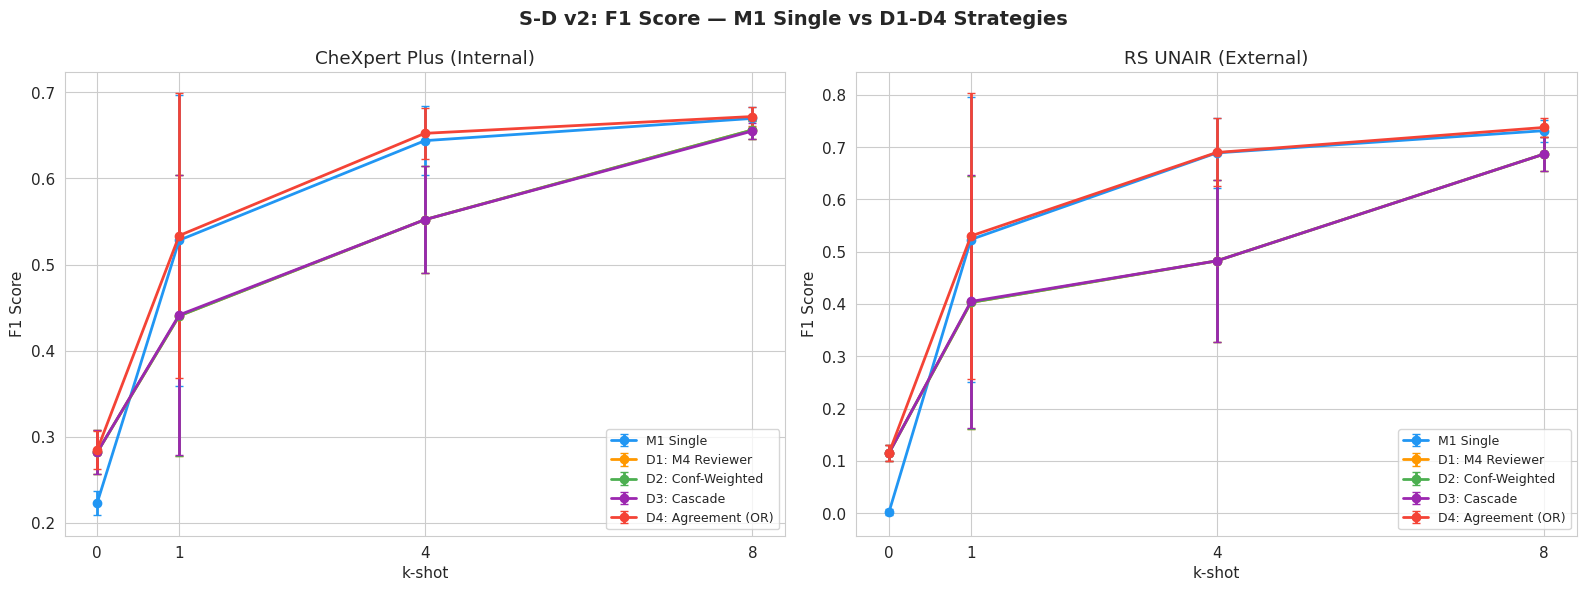

In [18]:
# Fig 1: F1 comparison across k-shots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
test_set_names = df_summary['test_set'].unique()

for ax_idx, ts in enumerate(test_set_names):
    ax = axes[ax_idx]
    sub = df_summary[df_summary['test_set'] == ts]
    
    for method in METHODS:
        msub = sub[sub['method'] == method]
        ax.errorbar(
            msub['k_shot'], msub['f1_mean'], yerr=msub['f1_std'],
            marker='o', label=METHOD_LABELS[method],
            color=METHOD_COLORS[method], capsize=3, linewidth=2,
        )
    
    ax.set_xlabel('k-shot')
    ax.set_ylabel('F1 Score')
    ax.set_title(ts)
    ax.legend(fontsize=9)
    ax.set_xticks(sorted(sub['k_shot'].unique()))

fig.suptitle('S-D v2: F1 Score — M1 Single vs D1-D4 Strategies', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'fig1_f1_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

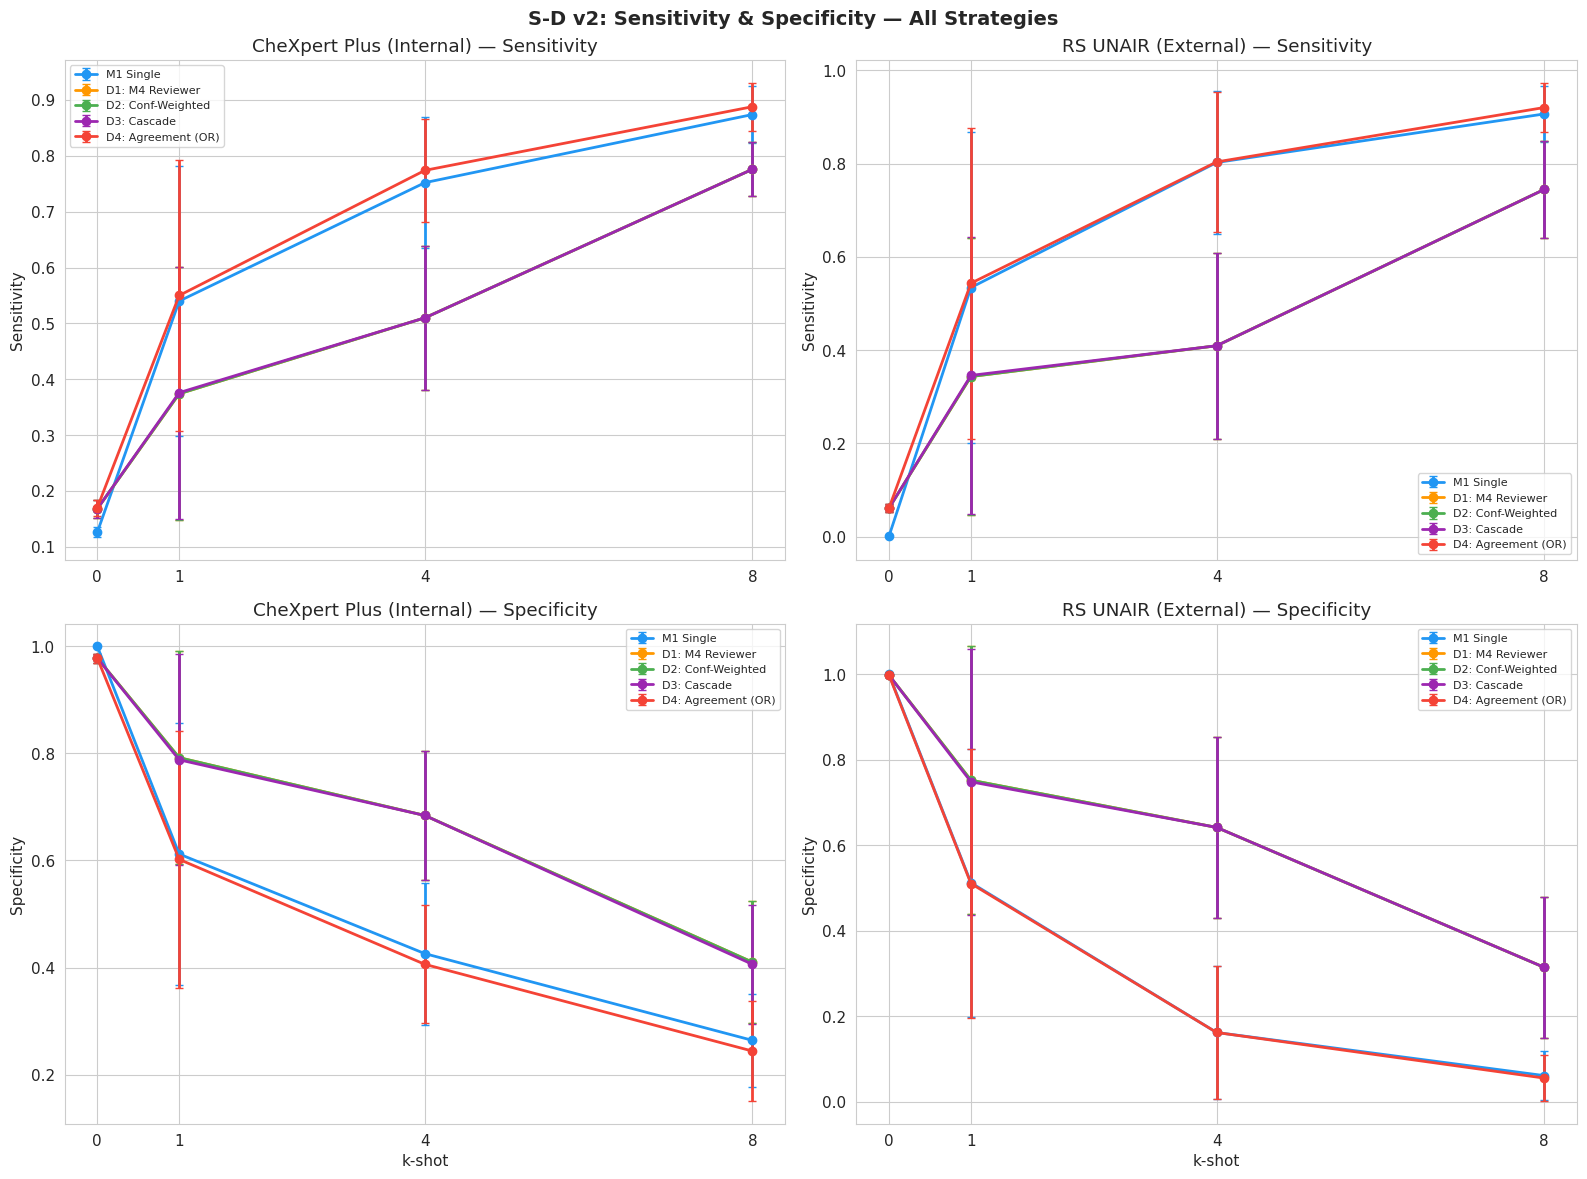

In [19]:
# Fig 2: Sensitivity & Specificity comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for col_idx, ts in enumerate(test_set_names):
    sub = df_summary[df_summary['test_set'] == ts]
    
    # Sensitivity
    ax = axes[0][col_idx]
    for method in METHODS:
        msub = sub[sub['method'] == method]
        ax.errorbar(
            msub['k_shot'], msub['sensitivity_mean'], yerr=msub['sensitivity_std'],
            marker='o', label=METHOD_LABELS[method],
            color=METHOD_COLORS[method], capsize=3, linewidth=2,
        )
    ax.set_ylabel('Sensitivity')
    ax.set_title(f'{ts} — Sensitivity')
    ax.legend(fontsize=8)
    ax.set_xticks(sorted(sub['k_shot'].unique()))
    
    # Specificity
    ax = axes[1][col_idx]
    for method in METHODS:
        msub = sub[sub['method'] == method]
        ax.errorbar(
            msub['k_shot'], msub['specificity_mean'], yerr=msub['specificity_std'],
            marker='o', label=METHOD_LABELS[method],
            color=METHOD_COLORS[method], capsize=3, linewidth=2,
        )
    ax.set_xlabel('k-shot')
    ax.set_ylabel('Specificity')
    ax.set_title(f'{ts} — Specificity')
    ax.legend(fontsize=8)
    ax.set_xticks(sorted(sub['k_shot'].unique()))

fig.suptitle('S-D v2: Sensitivity & Specificity — All Strategies', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'fig2_sens_spec.png', dpi=150, bbox_inches='tight')
plt.show()

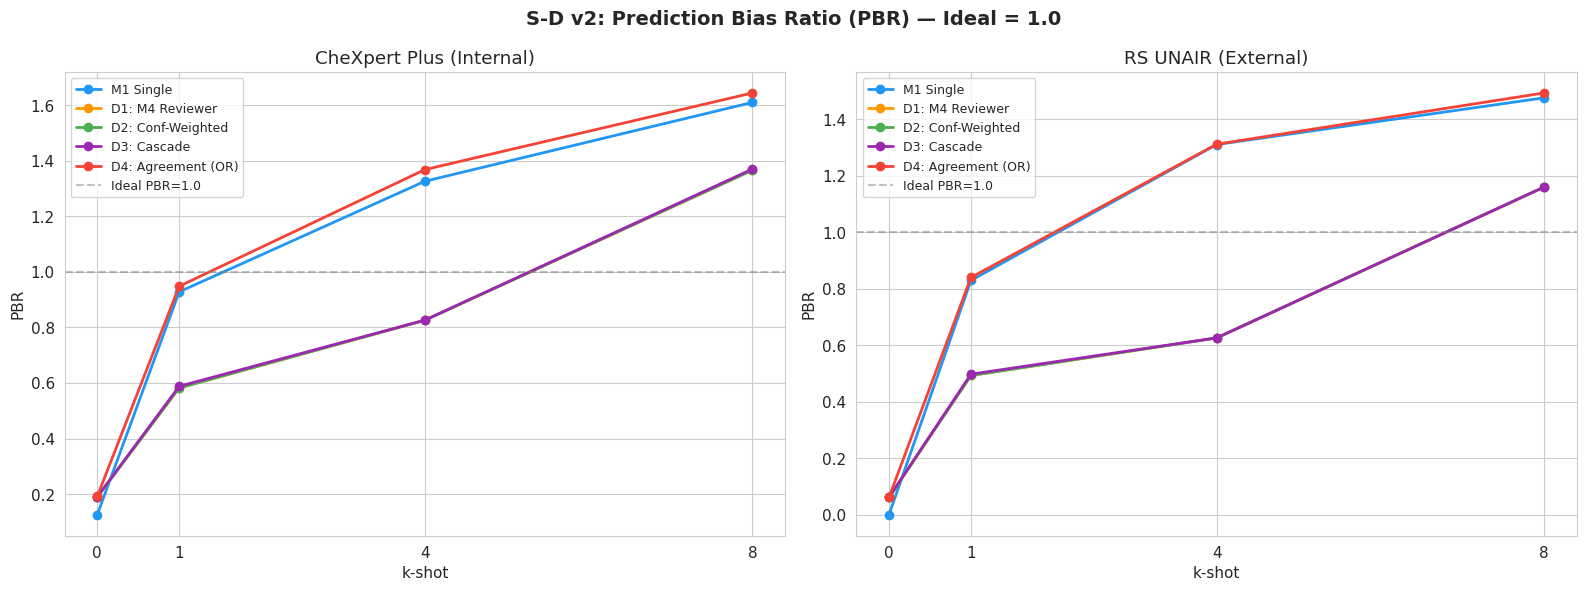

In [20]:
# Fig 3: PBR comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax_idx, ts in enumerate(test_set_names):
    ax = axes[ax_idx]
    sub = df_summary[df_summary['test_set'] == ts]
    
    for method in METHODS:
        msub = sub[sub['method'] == method]
        ax.plot(
            msub['k_shot'], msub['pbr_mean'],
            marker='o', label=METHOD_LABELS[method],
            color=METHOD_COLORS[method], linewidth=2,
        )
    
    ax.axhline(y=1.0, color='gray', linestyle='--', alpha=0.5, label='Ideal PBR=1.0')
    ax.set_xlabel('k-shot')
    ax.set_ylabel('PBR')
    ax.set_title(ts)
    ax.legend(fontsize=9)
    ax.set_xticks(sorted(sub['k_shot'].unique()))

fig.suptitle('S-D v2: Prediction Bias Ratio (PBR) — Ideal = 1.0', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'fig3_pbr.png', dpi=150, bbox_inches='tight')
plt.show()

## 14 — Confidence Distribution Analysis

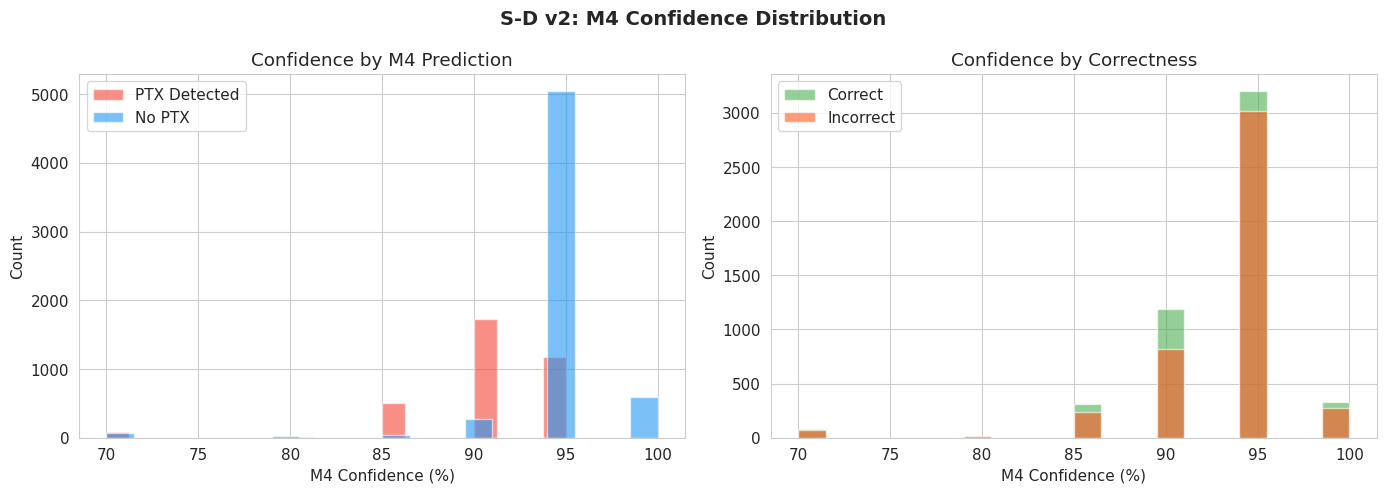


Confidence stats by correctness:
          count  mean  std   min   25%   50%   75%    max
correct                                                  
0        4442.0  93.4  4.5  70.0  90.0  95.0  95.0  100.0
1        5114.0  93.1  4.5  70.0  90.0  95.0  95.0  100.0


In [21]:
# Confidence distribution by prediction outcome
df_valid_conf = df_during[df_during['m4_confidence'] >= 0].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# By M4 prediction
ax = axes[0]
for pred, label, color in [(1, 'PTX Detected', '#F44336'), (0, 'No PTX', '#2196F3')]:
    subset = df_valid_conf[df_valid_conf['m4_predicted'] == pred]
    ax.hist(subset['m4_confidence'], bins=20, alpha=0.6, label=label, color=color)
ax.set_xlabel('M4 Confidence (%)')
ax.set_ylabel('Count')
ax.set_title('Confidence by M4 Prediction')
ax.legend()

# By correctness
ax = axes[1]
df_valid_conf['correct'] = (df_valid_conf['m4_predicted'] == df_valid_conf['ground_truth']).astype(int)
for correct, label, color in [(1, 'Correct', '#4CAF50'), (0, 'Incorrect', '#FF5722')]:
    subset = df_valid_conf[df_valid_conf['correct'] == correct]
    ax.hist(subset['m4_confidence'], bins=20, alpha=0.6, label=label, color=color)
ax.set_xlabel('M4 Confidence (%)')
ax.set_ylabel('Count')
ax.set_title('Confidence by Correctness')
ax.legend()

fig.suptitle('S-D v2: M4 Confidence Distribution', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'fig4_confidence_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# Stats
print('\nConfidence stats by correctness:')
print(df_valid_conf.groupby('correct')['m4_confidence'].describe().round(1))

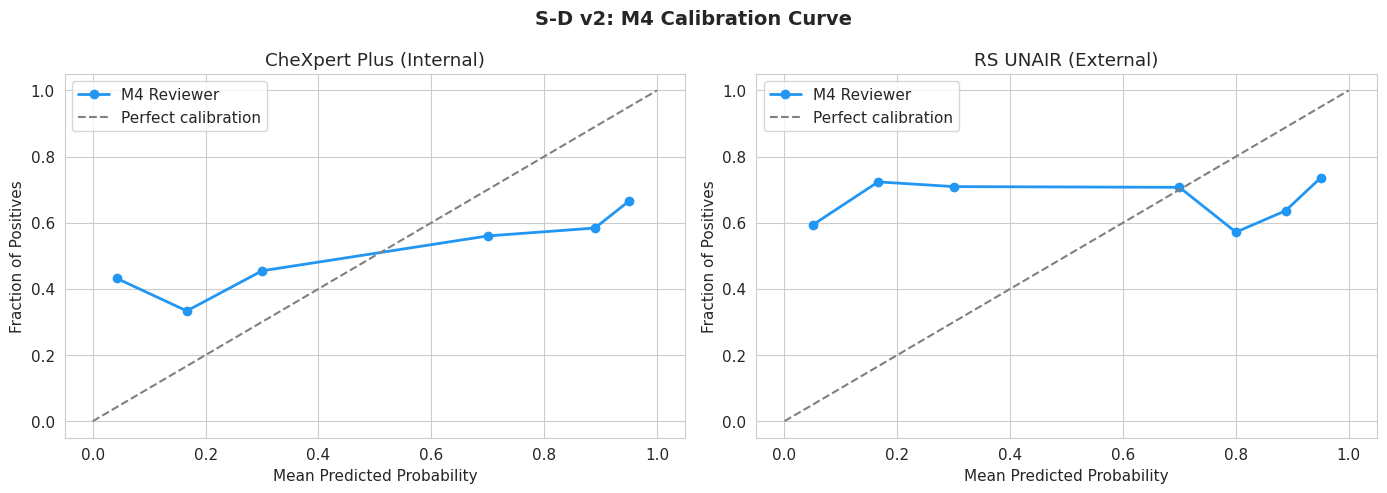

In [22]:
# Calibration curve: binned confidence vs actual accuracy
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax_idx, ts in enumerate(df_valid_conf['test_set'].unique()):
    ax = axes[ax_idx]
    sub = df_valid_conf[df_valid_conf['test_set'] == ts]
    
    # For PTX detection: confidence of positive prediction vs actual positive rate
    # Convert to probability scale (0-1)
    # If M4 predicts negative, use (100 - confidence) as probability of positive
    prob_positive = sub.apply(
        lambda r: r['m4_confidence'] / 100 if r['m4_predicted'] == 1 else (100 - r['m4_confidence']) / 100,
        axis=1
    )
    
    try:
        fraction_pos, mean_pred = calibration_curve(
            sub['ground_truth'], prob_positive, n_bins=10, strategy='uniform'
        )
        ax.plot(mean_pred, fraction_pos, 'o-', color='#2196F3', linewidth=2, label='M4 Reviewer')
        ax.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
    except Exception as e:
        ax.text(0.5, 0.5, f'Error: {e}', transform=ax.transAxes, ha='center')
    
    ax.set_xlabel('Mean Predicted Probability')
    ax.set_ylabel('Fraction of Positives')
    ax.set_title(ts)
    ax.legend()

fig.suptitle('S-D v2: M4 Calibration Curve', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'fig5_calibration.png', dpi=150, bbox_inches='tight')
plt.show()

## 15 — Statistical Tests

In [23]:
from scipy.stats import wilcoxon

print('=' * 80)
print('STATISTICAL TESTS — Wilcoxon signed-rank (paired across seeds)')
print('=' * 80)

for ts in df_metrics['test_set'].unique():
    print(f'\n── {ts} ──')
    sub = df_metrics[df_metrics['test_set'] == ts]
    
    for k in sorted(sub['k_shot'].unique()):
        print(f'\n  k={k}:')
        ksub = sub[sub['k_shot'] == k]
        m1_f1 = ksub[ksub['method'] == 'M1_single']['f1'].values
        
        for method in ['D1_M4_reviewer', 'D2_confidence_weighted', 'D3_threshold_cascade', 'D4_agreement_aware']:
            method_f1 = ksub[ksub['method'] == method]['f1'].values
            if len(m1_f1) == len(method_f1) and len(m1_f1) >= 5:
                diff = method_f1 - m1_f1
                mean_diff = diff.mean()
                try:
                    stat, p_val = wilcoxon(method_f1, m1_f1)
                    sig = '***' if p_val < 0.001 else '**' if p_val < 0.01 else '*' if p_val < 0.05 else 'ns'
                except Exception:
                    p_val = float('nan')
                    sig = 'N/A'
                print(f'    {method:30s} ΔF1={mean_diff:+.4f}  p={p_val:.4f} {sig}')

STATISTICAL TESTS — Wilcoxon signed-rank (paired across seeds)

── CheXpert Plus (Internal) ──

  k=0:
    D1_M4_reviewer                 ΔF1=+0.0585  p=0.0625 ns
    D2_confidence_weighted         ΔF1=+0.0585  p=0.0625 ns
    D3_threshold_cascade           ΔF1=+0.0585  p=0.0625 ns
    D4_agreement_aware             ΔF1=+0.0614  p=0.0625 ns

  k=1:
    D1_M4_reviewer                 ΔF1=-0.0878  p=0.0625 ns
    D2_confidence_weighted         ΔF1=-0.0878  p=0.0625 ns
    D3_threshold_cascade           ΔF1=-0.0867  p=0.0625 ns
    D4_agreement_aware             ΔF1=+0.0054  p=0.3750 ns

  k=4:
    D1_M4_reviewer                 ΔF1=-0.0917  p=0.0625 ns
    D2_confidence_weighted         ΔF1=-0.0917  p=0.0625 ns
    D3_threshold_cascade           ΔF1=-0.0917  p=0.0625 ns
    D4_agreement_aware             ΔF1=+0.0084  p=0.1875 ns

  k=8:
    D1_M4_reviewer                 ΔF1=-0.0134  p=0.0625 ns
    D2_confidence_weighted         ΔF1=-0.0134  p=0.0625 ns
    D3_threshold_cascade         

## 16 — Agreement Analysis

In [24]:
# M1 vs M4 reviewer agreement
df_during['agreement'] = (df_during['m1_predicted'] == df_during['m4_predicted']).astype(int)

print('M1 vs M4 Reviewer Agreement:')
for ts in df_during['test_set'].unique():
    print(f'\n  {ts}:')
    sub = df_during[df_during['test_set'] == ts]
    for k in sorted(sub['k_shot'].unique()):
        ksub = sub[sub['k_shot'] == k]
        agree_rate = ksub['agreement'].mean()
        
        # Breakdown of disagreements
        m1_pos_m4_neg = ((ksub['m1_predicted'] == 1) & (ksub['m4_predicted'] == 0)).sum()
        m1_neg_m4_pos = ((ksub['m1_predicted'] == 0) & (ksub['m4_predicted'] == 1)).sum()
        
        print(f'    k={k}: agree={agree_rate:.1%}  '
              f'M1+/M4-={m1_pos_m4_neg}  M1-/M4+={m1_neg_m4_pos}')

# Confidence in agreement vs disagreement
print('\nM4 Confidence by agreement:')
conf_agree = df_during.loc[(df_during['agreement'] == 1) & (df_during['m4_confidence'] >= 0), 'm4_confidence']
conf_disagree = df_during.loc[(df_during['agreement'] == 0) & (df_during['m4_confidence'] >= 0), 'm4_confidence']
print(f'  Agree:    mean={conf_agree.mean():.1f}%, median={conf_agree.median():.0f}%, n={len(conf_agree)}')
print(f'  Disagree: mean={conf_disagree.mean():.1f}%, median={conf_disagree.median():.0f}%, n={len(conf_disagree)}')

M1 vs M4 Reviewer Agreement:

  CheXpert Plus (Internal):
    k=0: agree=96.6%  M1+/M4-=1  M1-/M4+=33
    k=1: agree=80.7%  M1+/M4-=183  M1-/M4+=10
    k=4: agree=70.8%  M1+/M4-=271  M1-/M4+=21
    k=8: agree=84.4%  M1+/M4-=139  M1-/M4+=17

  RS UNAIR (External):
    k=0: agree=96.2%  M1+/M4-=0  M1-/M4+=53
    k=1: agree=77.8%  M1+/M4-=300  M1-/M4+=9
    k=4: agree=57.3%  M1+/M4-=593  M1-/M4+=1
    k=8: agree=78.2%  M1+/M4-=288  M1-/M4+=15

M4 Confidence by agreement:
  Agree:    mean=93.1%, median=95%, n=7623
  Disagree: mean=94.0%, median=95%, n=1933


## 17 — Qualitative Examples

In [25]:
# Show interesting cases for each category
sample_k = 4  # Use k=4 for examples
sample_seed = 0

sub = df_during[
    (df_during['k_shot'] == sample_k) & (df_during['seed'] == sample_seed)
].copy()

print(f'Qualitative examples (k={sample_k}, seed={sample_seed})')
print(f'Total: {len(sub)} records\n')

cases = {
    'M4 CORRECTS M1 (FP→TN)': sub[(sub['m1_predicted'] == 1) & (sub['m4_predicted'] == 0) & (sub['ground_truth'] == 0)],
    'M4 OVERCORRECTS (TP→FN)': sub[(sub['m1_predicted'] == 1) & (sub['m4_predicted'] == 0) & (sub['ground_truth'] == 1)],
    'M4 ADDS DETECTION (FN→TP)': sub[(sub['m1_predicted'] == 0) & (sub['m4_predicted'] == 1) & (sub['ground_truth'] == 1)],
    'BOTH AGREE POSITIVE (TP)': sub[(sub['m1_predicted'] == 1) & (sub['m4_predicted'] == 1) & (sub['ground_truth'] == 1)],
}

for case_name, case_df in cases.items():
    n = len(case_df)
    print(f'\n{"═" * 70}')
    print(f'{case_name}: {n} cases')
    print(f'{"═" * 70}')
    
    if n > 0:
        # Show 2 examples
        for _, row in case_df.head(2).iterrows():
            print(f"\n  Image: {row['image_id']} ({row['test_set']})")
            print(f"  GT={row['ground_truth']}, M1={row['m1_predicted']}, M4={row['m4_predicted']}")
            conf = row['m4_confidence']
            print(f"  M4 Confidence: {conf:.0f}%" if conf >= 0 else "  M4 Confidence: N/A")
            print(f"  M4 Output (first 300 chars):")
            print(f"    {row['m4_generated_text'][:300]}")

Qualitative examples (k=4, seed=0)
Total: 478 records


══════════════════════════════════════════════════════════════════════
M4 CORRECTS M1 (FP→TN): 46 cases
══════════════════════════════════════════════════════════════════════

  Image: patient03254_study1_view1_frontal (CheXpert Plus (Internal))
  GT=0, M1=1, M4=0
  M4 Confidence: 95%
  M4 Output (first 300 chars):
    FIRST READER EVALUATION: The first reader identified linear atelectasis in the right mid lung, small bilateral pleural effusions, and left basilar opacities. They also noted a central venous catheter.

MY OBSERVATIONS: The lungs appear relatively clear, with no obvious consolidation or large infiltr

  Image: patient32621_study1_view1_frontal (CheXpert Plus (Internal))
  GT=0, M1=1, M4=0
  M4 Confidence: 95%
  M4 Output (first 300 chars):
    FIRST READER EVALUATION: The first reader identified bilateral opacities and possible pleural effusions. They also noted a feeding tube.

MY OBSERVATIONS: The lungs appear rela

## 18 — D2/D3 Threshold Sensitivity Analysis

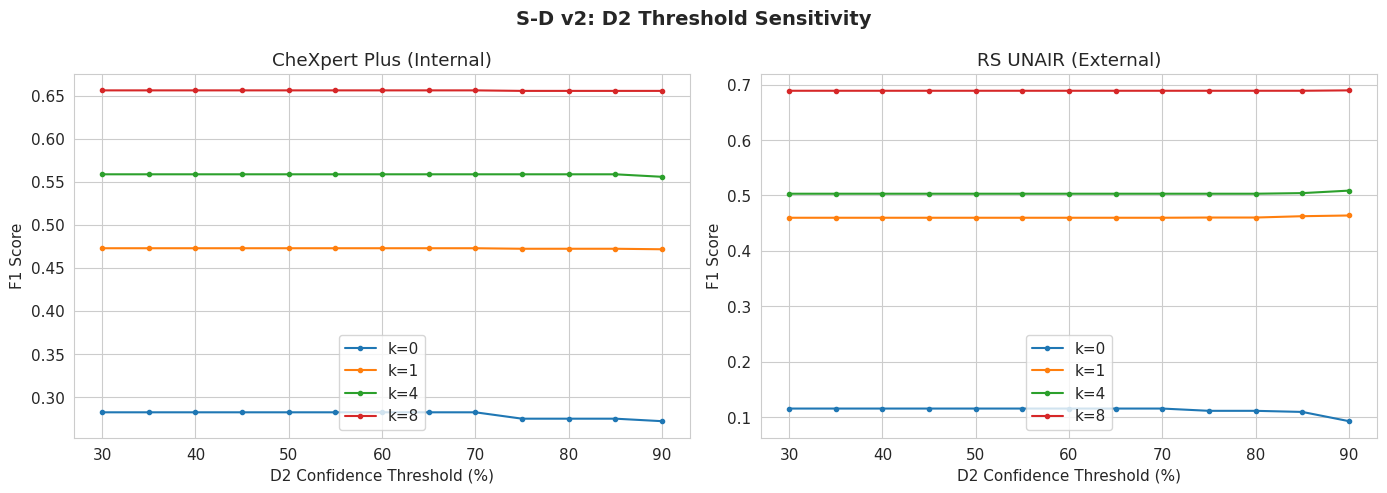

In [26]:
# Sweep D2 threshold to find optimal
d2_thresholds = range(30, 95, 5)
d2_sweep_rows = []

for thresh in d2_thresholds:
    df_during['_d2_temp'] = df_during.apply(lambda r: d2_confidence_weighted(r, threshold=thresh), axis=1)
    
    for (k, ts), grp in df_during.groupby(['k_shot', 'test_set']):
        gt = grp['ground_truth'].tolist()
        preds = grp['_d2_temp'].tolist()
        metrics = compute_classification_metrics(gt, preds)
        d2_sweep_rows.append({
            'threshold': thresh, 'k_shot': k, 'test_set': ts, **metrics,
        })

df_d2_sweep = pd.DataFrame(d2_sweep_rows)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax_idx, ts in enumerate(df_d2_sweep['test_set'].unique()):
    ax = axes[ax_idx]
    sub = df_d2_sweep[df_d2_sweep['test_set'] == ts]
    
    for k in sorted(sub['k_shot'].unique()):
        ksub = sub[sub['k_shot'] == k]
        ax.plot(ksub['threshold'], ksub['f1'], marker='.', label=f'k={k}')
    
    ax.set_xlabel('D2 Confidence Threshold (%)')
    ax.set_ylabel('F1 Score')
    ax.set_title(ts)
    ax.legend()

fig.suptitle('S-D v2: D2 Threshold Sensitivity', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'fig6_d2_threshold_sweep.png', dpi=150, bbox_inches='tight')
plt.show()

# Clean up temp column
df_during.drop(columns=['_d2_temp'], inplace=True, errors='ignore')

In [27]:
# Sweep D3 thresholds (tau_high, tau_low)
d3_sweep_rows = []

for tau_high in [60, 70, 80, 90]:
    for tau_low in [20, 30, 40, 50]:
        if tau_low >= tau_high:
            continue
        df_during['_d3_temp'] = df_during.apply(
            lambda r: d3_threshold_cascade(r, tau_high=tau_high, tau_low=tau_low), axis=1
        )
        
        for (k, ts), grp in df_during.groupby(['k_shot', 'test_set']):
            gt = grp['ground_truth'].tolist()
            preds = grp['_d3_temp'].tolist()
            metrics = compute_classification_metrics(gt, preds)
            d3_sweep_rows.append({
                'tau_high': tau_high, 'tau_low': tau_low,
                'k_shot': k, 'test_set': ts, **metrics,
            })

df_d3_sweep = pd.DataFrame(d3_sweep_rows)

# Find best tau_high/tau_low per k and test_set
print('Best D3 thresholds by F1:')
for (k, ts), grp in df_d3_sweep.groupby(['k_shot', 'test_set']):
    best = grp.loc[grp['f1'].idxmax()]
    print(f'  k={k}, {ts}: tau_high={best["tau_high"]:.0f}, tau_low={best["tau_low"]:.0f}, '
          f'F1={best["f1"]:.4f}, Sens={best["sensitivity"]:.4f}, Spec={best["specificity"]:.4f}')

df_during.drop(columns=['_d3_temp'], inplace=True, errors='ignore')

Best D3 thresholds by F1:
  k=0, CheXpert Plus (Internal): tau_high=60, tau_low=20, F1=0.2824, Sens=0.1680, Spec=0.9780
  k=0, RS UNAIR (External): tau_high=60, tau_low=20, F1=0.1153, Sens=0.0613, Spec=0.9981
  k=1, CheXpert Plus (Internal): tau_high=90, tau_low=20, F1=0.4749, Sens=0.3780, Spec=0.7860
  k=1, RS UNAIR (External): tau_high=90, tau_low=20, F1=0.4706, Sens=0.3561, Spec=0.7410
  k=4, CheXpert Plus (Internal): tau_high=60, tau_low=20, F1=0.5586, Sens=0.5100, Spec=0.6840
  k=4, RS UNAIR (External): tau_high=90, tau_low=20, F1=0.5088, Sens=0.4162, Spec=0.6381
  k=8, CheXpert Plus (Internal): tau_high=60, tau_low=20, F1=0.6560, Sens=0.7760, Spec=0.4100
  k=8, RS UNAIR (External): tau_high=90, tau_low=20, F1=0.6929, Sens=0.7526, Spec=0.3086


## 19 — Cross-Scenario Comparison (S-A vs S-C v2 vs S-D v2)

Load results dari skenario sebelumnya untuk perbandingan.

In [28]:
# Attempt to load S-C v2 results for comparison
sc_v2_dir = Path('results-during-ensemble-m1-m4-reasoning')
sa_dir = Path('results-ensemble-m1-m4')  # after-inference

comparison_data = {}

# S-D v2 (current)
comparison_data['S-D_v2_D1'] = df_metrics[df_metrics['method'] == 'D1_M4_reviewer'].copy()
comparison_data['S-D_v2_D2'] = df_metrics[df_metrics['method'] == 'D2_confidence_weighted'].copy()
comparison_data['S-D_v2_D3'] = df_metrics[df_metrics['method'] == 'D3_threshold_cascade'].copy()
comparison_data['S-D_v2_D4'] = df_metrics[df_metrics['method'] == 'D4_agreement_aware'].copy()

# Try loading S-C v2
sc_csv = sc_v2_dir / 'during_ensemble_reasoning_per_seed.csv'
if sc_csv.exists():
    df_sc = pd.read_csv(sc_csv)
    comparison_data['S-C_v2'] = df_sc[df_sc['method'] == 'During_M1toM4_Reasoning'].copy()
    print(f'Loaded S-C v2: {len(comparison_data["S-C_v2"])} rows')
else:
    print(f'S-C v2 not found at {sc_csv}')

# M1 single (baseline)
comparison_data['M1_single'] = df_metrics[df_metrics['method'] == 'M1_single'].copy()

print(f'\nLoaded {len(comparison_data)} scenario results for comparison')

S-C v2 not found at results-during-ensemble-m1-m4-reasoning/during_ensemble_reasoning_per_seed.csv

Loaded 5 scenario results for comparison


In [29]:
# Cross-scenario comparison table
print('=' * 100)
print('CROSS-SCENARIO COMPARISON — Mean F1 across seeds')
print('=' * 100)

for ts in df_metrics['test_set'].unique():
    print(f'\n── {ts} ──')
    print(f'{"Scenario":35s} {"k=0":>10s} {"k=1":>10s} {"k=4":>10s} {"k=8":>10s}')
    print('─' * 75)
    
    for scenario_name, scenario_df in comparison_data.items():
        sub = scenario_df[scenario_df['test_set'] == ts] if 'test_set' in scenario_df.columns else scenario_df
        vals = []
        for k in [0, 1, 4, 8]:
            ksub = sub[sub['k_shot'] == k] if 'k_shot' in sub.columns else pd.DataFrame()
            if len(ksub) > 0:
                vals.append(f"{ksub['f1'].mean():.3f}")
            else:
                vals.append('—')
        print(f'{scenario_name:35s} {vals[0]:>10s} {vals[1]:>10s} {vals[2]:>10s} {vals[3]:>10s}')

CROSS-SCENARIO COMPARISON — Mean F1 across seeds

── CheXpert Plus (Internal) ──
Scenario                                   k=0        k=1        k=4        k=8
───────────────────────────────────────────────────────────────────────────
S-D_v2_D1                                0.282      0.440      0.552      0.656
S-D_v2_D2                                0.282      0.440      0.552      0.656
S-D_v2_D3                                0.282      0.442      0.552      0.655
S-D_v2_D4                                0.285      0.534      0.652      0.672
M1_single                                0.224      0.528      0.644      0.670

── RS UNAIR (External) ──
Scenario                                   k=0        k=1        k=4        k=8
───────────────────────────────────────────────────────────────────────────
S-D_v2_D1                                0.115      0.403      0.482      0.687
S-D_v2_D2                                0.115      0.403      0.482      0.687
S-D_v2_D3           

## 20 — Key Findings

In [30]:
print('=' * 80)
print('KEY FINDINGS — S-D v2: During-Inference M1→M4 with Confidence')
print('=' * 80)

# Best strategy
best_rows = []
for (k, ts), grp in df_metrics.groupby(['k_shot', 'test_set']):
    # Exclude M1_single
    ensemble_methods = grp[grp['method'] != 'M1_single']
    if len(ensemble_methods) > 0:
        best = ensemble_methods.groupby('method')['f1'].mean().idxmax()
        best_f1 = ensemble_methods.groupby('method')['f1'].mean().max()
        m1_f1 = grp[grp['method'] == 'M1_single']['f1'].mean()
        best_rows.append({
            'k': k, 'test_set': ts, 'best_method': best,
            'best_f1': best_f1, 'm1_f1': m1_f1, 'delta': best_f1 - m1_f1,
        })

df_best = pd.DataFrame(best_rows)
print('\nBest strategy per (k, test_set):')
for _, row in df_best.iterrows():
    symbol = '↑' if row['delta'] > 0 else '↓'
    print(f"  k={row['k']}, {row['test_set']}: {row['best_method']} "
          f"F1={row['best_f1']:.3f} (M1={row['m1_f1']:.3f}, Δ={row['delta']:+.3f} {symbol})")

# Confidence stats
print('\nConfidence extraction rate:', f"{(df_during['m4_confidence'] >= 0).mean():.1%}")
print(f"Mean confidence: {df_during.loc[df_during['m4_confidence'] >= 0, 'm4_confidence'].mean():.1f}%")

KEY FINDINGS — S-D v2: During-Inference M1→M4 with Confidence

Best strategy per (k, test_set):
  k=0, CheXpert Plus (Internal): D4_agreement_aware F1=0.285 (M1=0.224, Δ=+0.061 ↑)
  k=0, RS UNAIR (External): D1_M4_reviewer F1=0.115 (M1=0.002, Δ=+0.113 ↑)
  k=1, CheXpert Plus (Internal): D4_agreement_aware F1=0.534 (M1=0.528, Δ=+0.005 ↑)
  k=1, RS UNAIR (External): D4_agreement_aware F1=0.530 (M1=0.523, Δ=+0.007 ↑)
  k=4, CheXpert Plus (Internal): D4_agreement_aware F1=0.652 (M1=0.644, Δ=+0.008 ↑)
  k=4, RS UNAIR (External): D4_agreement_aware F1=0.690 (M1=0.689, Δ=+0.001 ↑)
  k=8, CheXpert Plus (Internal): D4_agreement_aware F1=0.672 (M1=0.670, Δ=+0.002 ↑)
  k=8, RS UNAIR (External): D4_agreement_aware F1=0.738 (M1=0.731, Δ=+0.006 ↑)

Confidence extraction rate: 100.0%
Mean confidence: 93.3%


## 21 — Export

In [31]:
print('EXPORTED FILES:')
print(f'\nResults:')
for f in sorted(OUTPUT_DIR.glob('*')):
    size_mb = f.stat().st_size / 1e6
    print(f'  {f.name} ({size_mb:.1f} MB)')

print(f'\nTotal files: {len(list(OUTPUT_DIR.glob("*")))}')

EXPORTED FILES:

Results:
  all_results_sd_v2.jsonl (36.2 MB)
  checkpoint_sd_v2.jsonl (36.4 MB)
  fig1_f1_comparison.png (0.2 MB)
  fig2_sens_spec.png (0.4 MB)
  fig3_pbr.png (0.2 MB)
  fig4_confidence_distribution.png (0.1 MB)
  fig5_calibration.png (0.1 MB)
  fig6_d2_threshold_sweep.png (0.1 MB)
  sd_v2_per_seed_metrics.csv (0.0 MB)
  sd_v2_summary.csv (0.0 MB)

Total files: 10
